<a href="https://colab.research.google.com/github/chimmy003/COU07506_WEEK2_240242496495/blob/main/COU07506_WEEK2_240242496495.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NAME: CHIMILO CHIMILO LABAN
REG NO: 240242496495
CLASS: BENG24COE-3

Task 2.1 — Aliasing of a sinusoid
This code plots the original 7 Hz signal, its alias, and the sampled points. It also calculates the alias frequencies for sampling rates 10, 12, 14, and 20 Hz.


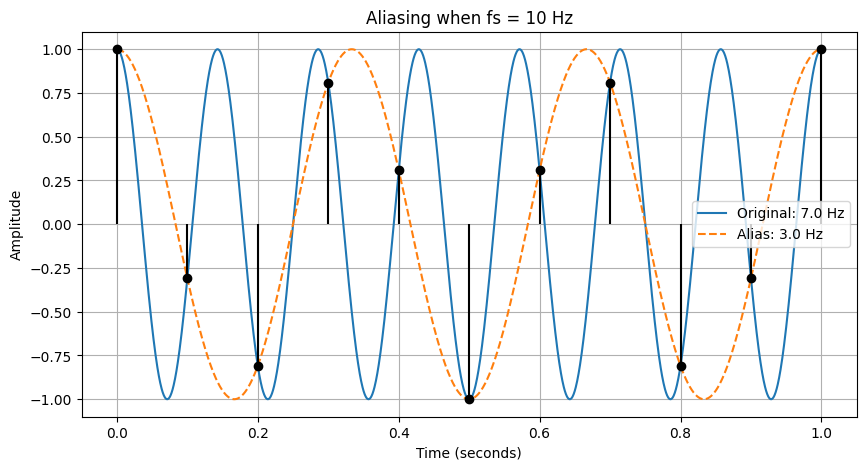

Sampling frequency = 10 Hz
Nyquist frequency = 5.0 Hz
Alias frequency = 3.0 Hz
-----------------------------


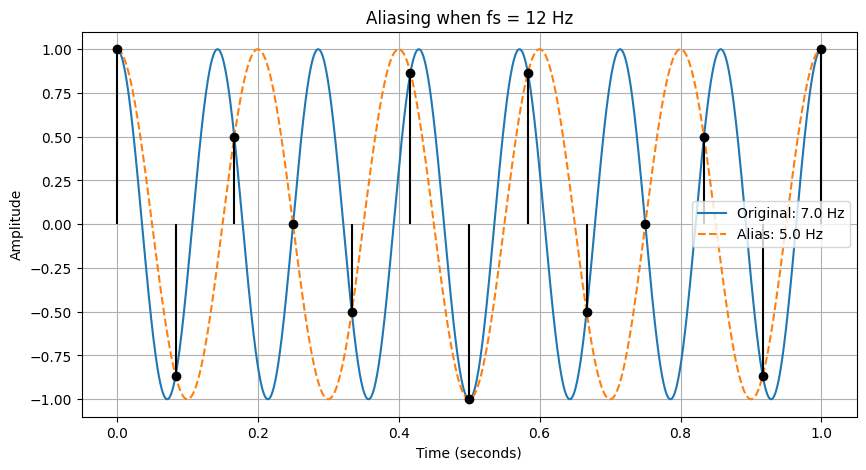

Sampling frequency = 12 Hz
Nyquist frequency = 6.0 Hz
Alias frequency = 5.0 Hz
-----------------------------


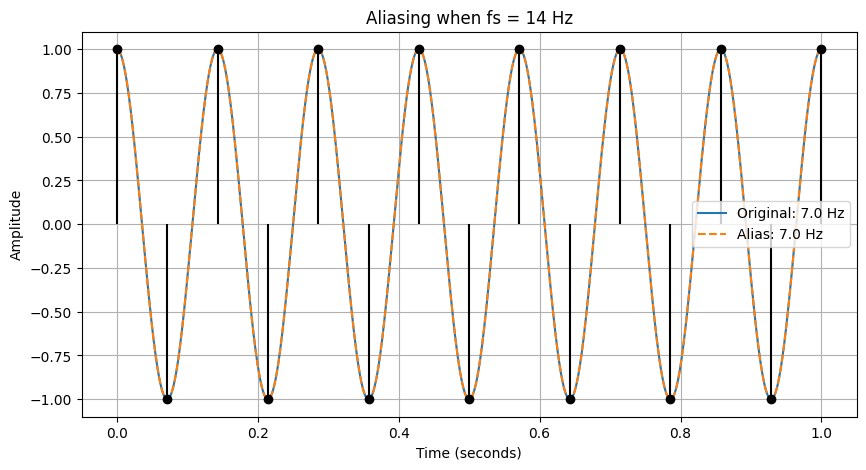

Sampling frequency = 14 Hz
Nyquist frequency = 7.0 Hz
Alias frequency = 7.0 Hz
-----------------------------


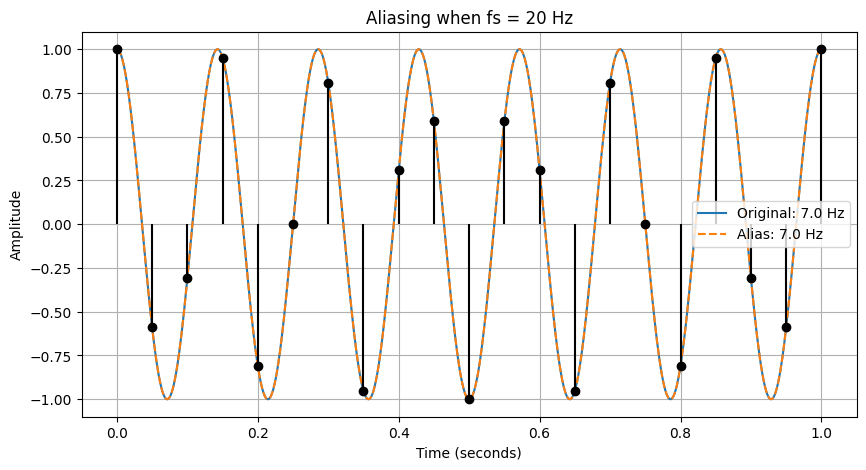

Sampling frequency = 20 Hz
Nyquist frequency = 10.0 Hz
Alias frequency = 7.0 Hz
-----------------------------


In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Original signal frequency
f0 = 7.0

# Sampling frequencies to test
sampling_rates = [10, 12, 14, 20]

# Create a smooth time axis for the original signal
t = np.linspace(0, 1, 2000)

# Plot each sampling-rate case
for fs in sampling_rates:

    # Sampling points
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Calculate alias frequency
    f_alias = abs(f0 - fs * round(f0 / fs))

    # Original continuous-looking signal
    x = np.cos(2 * np.pi * f0 * t)

    # Alias signal
    x_alias = np.cos(2 * np.pi * f_alias * t)

    # Actual sampled signal values
    xn = np.cos(2 * np.pi * f0 * tn)

    # Plot
    plt.figure(figsize=(10, 5))
    plt.plot(t, x, label=f"Original: {f0} Hz")
    plt.plot(t, x_alias, "--", label=f"Alias: {f_alias} Hz")

    plt.stem(
        tn, xn,
        linefmt="k-",
        markerfmt="ko",
        basefmt=" "
    )

    plt.title(f"Aliasing when fs = {fs} Hz")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.legend()
    plt.show()

    print(f"Sampling frequency = {fs} Hz")
    print(f"Nyquist frequency = {fs / 2} Hz")
    print(f"Alias frequency = {f_alias} Hz")
    print("-----------------------------")

Task 2.2 — Hear aliasing
This task compares:
- Naïve downsampling: keeps every \(k\)-th sample without filtering.
- Proper downsampling: applies an anti-aliasing low-pass filter before reducing the sample rate.

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

# Name of your Week 1 voice recording
fname = "my_voice.wav"

# Load your recording if it exists
if os.path.exists(fname):

    fs, x = wavfile.read(fname)

    # Convert stereo recording to mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    # Convert audio to floating-point values
    x = x.astype(float)

    # Normalize audio to the range approximately -1 to 1
    x = x / np.max(np.abs(x))

else:
    # Fallback signal: chirp from 200 Hz to 15 kHz
    fs = 44100

    t = np.arange(0, 3, 1 / fs)

    x = 0.5 * signal.chirp(
        t,
        f0=200,
        t1=3,
        f1=15000
    )

print("Original sampling rate:", fs, "Hz")

# Downsample using k = 2, 4 and 8
for k in [2, 4, 8]:

    # Naïve downsampling without anti-aliasing filter
    naive = x[::k]

    # Proper downsampling with anti-aliasing filter
    proper = signal.decimate(
        x,
        k,
        ftype="fir"
    )

    # New sampling rate
    new_fs = fs // k

    print("\nDownsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    # Listen to naïve signal
    print("Naive downsampling:")
    display(Audio(naive, rate=new_fs))

    # Listen to filtered signal
    print("Filtered downsampling:")
    display(Audio(proper, rate=new_fs))

Original sampling rate: 44100 Hz

Downsampling factor: 2
New sampling rate: 22050 Hz
Naive downsampling:


Filtered downsampling:



Downsampling factor: 4
New sampling rate: 11025 Hz
Naive downsampling:


Filtered downsampling:



Downsampling factor: 8
New sampling rate: 5512 Hz
Naive downsampling:


Filtered downsampling:


Task 2.3 — A uniform quantizer
This code creates a 300 Hz sine wave, quantizes it to 3 bits, and plots the original signal, quantized signal, and quantization error.

Number of bits: 3
Quantization step size: 0.25


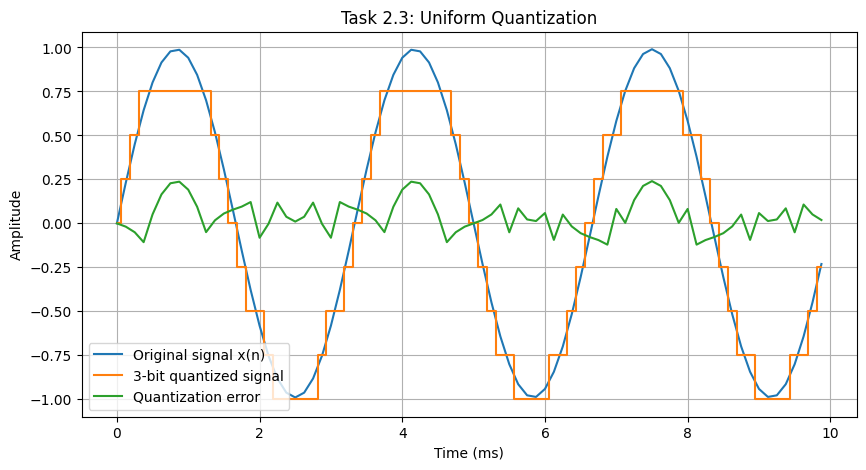

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Uniform quantizer function
def quantize(x, bits, full_scale=1.0):

    # Calculate quantization step size
    delta = 2 * full_scale / (2 ** bits)

    # Quantize the signal
    q = np.round(x / delta) * delta

    # Limit values to the allowed quantizer range
    q = np.clip(q, -full_scale, full_scale - delta)

    return q


# Sampling frequency
fs = 8000

# Create time axis for 10 milliseconds
t = np.arange(0, 0.01, 1 / fs)

# Generate a 300 Hz sine wave
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Quantize the signal to 3 bits
xq = quantize(x, 3)

# Calculate quantization error
error = x - xq

# Calculate step size
delta = 2 / (2 ** 3)

print("Number of bits: 3")
print("Quantization step size:", delta)

# Plot original signal
plt.figure(figsize=(10, 5))
plt.plot(t * 1000, x, label="Original signal x(n)")

# Plot quantized signal
plt.step(t * 1000, xq, where="mid", label="3-bit quantized signal")

# Plot quantization error
plt.plot(t * 1000, error, label="Quantization error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Task 2.3: Uniform Quantization")
plt.grid(True)
plt.legend()
plt.show()

Task 2.4 — Verify the 6 dB-per-bit rule
This code measures the SQNR for 2, 4, 6, …, 16 bits and compares it with the theoretical formula.
\[
SQNR_{\text{theoretical}}=6.02B+1.76
\]

2-bit: Measured SQNR = 9.56 dB, Theoretical SQNR = 13.80 dB
4-bit: Measured SQNR = 23.27 dB, Theoretical SQNR = 25.84 dB
6-bit: Measured SQNR = 35.61 dB, Theoretical SQNR = 37.88 dB
8-bit: Measured SQNR = 49.29 dB, Theoretical SQNR = 49.92 dB
10-bit: Measured SQNR = 61.35 dB, Theoretical SQNR = 61.96 dB
12-bit: Measured SQNR = 75.05 dB, Theoretical SQNR = 74.00 dB
14-bit: Measured SQNR = 85.30 dB, Theoretical SQNR = 86.04 dB
16-bit: Measured SQNR = 97.28 dB, Theoretical SQNR = 98.08 dB


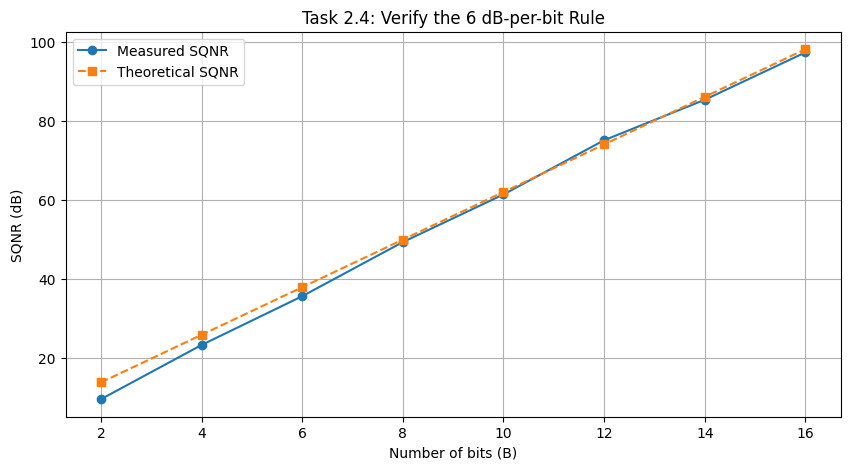

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a full-scale sine wave
fs = 8000
t = np.arange(0, 1, 1 / fs)

x = np.sin(2 * np.pi * 300 * t)

# Bit depths to test
bits = np.arange(2, 17, 2)

# Lists to store results
measured_sqnr = []
theoretical_sqnr = []

# Calculate SQNR for each bit depth
for B in bits:

    # Quantize the signal
    xq = quantize(x, B)

    # Calculate quantization error
    error = x - xq

    # Calculate measured SQNR
    sqnr_measured = 10 * np.log10(
        np.sum(x ** 2) / np.sum(error ** 2)
    )

    # Calculate theoretical SQNR
    sqnr_theoretical = 6.02 * B + 1.76

    # Store results
    measured_sqnr.append(sqnr_measured)
    theoretical_sqnr.append(sqnr_theoretical)

    print(
        f"{B}-bit: Measured SQNR = "
        f"{sqnr_measured:.2f} dB, "
        f"Theoretical SQNR = {sqnr_theoretical:.2f} dB"
    )

# Plot measured and theoretical SQNR
plt.figure(figsize=(10, 5))

plt.plot(
    bits,
    measured_sqnr,
    "o-",
    label="Measured SQNR"
)

plt.plot(
    bits,
    theoretical_sqnr,
    "s--",
    label="Theoretical SQNR"
)

plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Task 2.4: Verify the 6 dB-per-bit Rule")
plt.grid(True)
plt.legend()
plt.show()

Task 2.5 — Quantize your voice
This code quantizes your voice recording to 4, 8, and 12 bits, plays each version, and calculates the measured SQNR.


Quantization: 4 bits
Measured SQNR: 23.27 dB



Quantization: 8 bits
Measured SQNR: 49.29 dB



Quantization: 12 bits
Measured SQNR: 75.05 dB


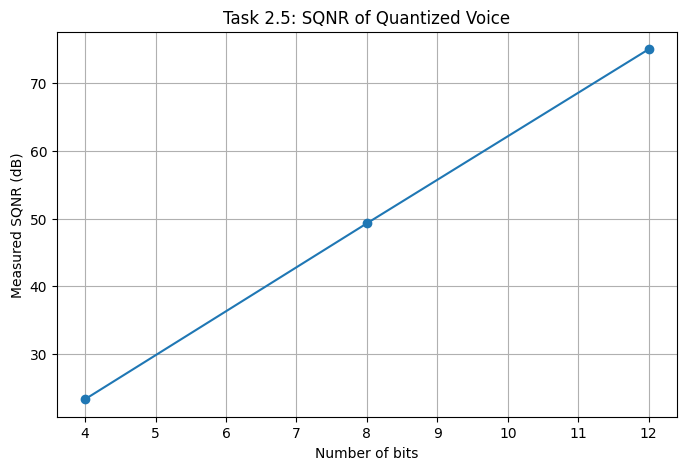

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Use the voice recording loaded in Task 2.2
# x = normalized voice signal
# fs = original sampling frequency

# Make sure the signal is normalized
x = x.astype(float)

if np.max(np.abs(x)) > 0:
    x = x / np.max(np.abs(x))

# Bit depths to test
bit_depths = [4, 8, 12]

# Store SQNR results
sqnr_results = []

# Process each bit depth
for B in bit_depths:

    # Quantize the voice recording
    xq = quantize(x, B)

    # Calculate quantization error
    error = x - xq

    # Calculate measured SQNR
    sqnr = 10 * np.log10(
        np.sum(x ** 2) / np.sum(error ** 2)
    )

    # Store result
    sqnr_results.append(sqnr)

    print(f"\nQuantization: {B} bits")
    print(f"Measured SQNR: {sqnr:.2f} dB")

    # Play the quantized voice
    display(Audio(xq, rate=fs))

# Plot SQNR results
plt.figure(figsize=(8, 5))

plt.plot(
    bit_depths,
    sqnr_results,
    "o-"
)

plt.xlabel("Number of bits")
plt.ylabel("Measured SQNR (dB)")
plt.title("Task 2.5: SQNR of Quantized Voice")
plt.grid(True)
plt.show()

## Week 2 - Lab 1A: Analysis Questions & Solutions

### 1. Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s = 10$ Hz.

**Mathematical Derivation:**
When a continuous-time cosine wave $x(t) = \cos(2\pi f_0 t)$ with $f_0 = 7\text{ Hz}$ is sampled at a rate of $f_s = 10\text{ Hz}$, the resulting discrete-time sequence is:
$$x[n] = \cos\left(2\pi f_0 \frac{n}{f_s}\right) = \cos\left(2\pi \frac{7}{10} n\right) = \cos\left(1.4\pi n\right)$$

Since discrete-time frequencies are periodic with a period of $2\pi$, we can express this frequency as:
$$\cos(1.4\pi n) = \cos(1.4\pi n - 2\pi n) = \cos(-0.6\pi n)$$

Since cosine is an even function ($\cos(-\theta) = \cos(\theta)$):
$$\cos(-0.6\pi n) = \cos(0.6\pi n) = \cos\left(2\pi \frac{3}{10} n\right)$$

Reconstructing this back into a continuous-time signal using ideal interpolation yields an apparent alias frequency of **$3\text{ Hz}$**.

**Frequency-Axis Explanation:**
In the continuous frequency domain, a $7\text{ Hz}$ cosine wave consists of two Dirac delta impulses located at $\pm f_0 = \pm 7\text{ Hz}$.
Sampling repeats these spectral components at all integer multiples of the sampling frequency $f_s = 10\text{ Hz}$:
$$F_{\text{sampled}} = f_0 + k f_s \quad \text{and} \quad -f_0 + k f_s \quad (k \in \mathbb{Z})$$

* For $k = -1$: $+7\text{ Hz} - 10\text{ Hz} = -3\text{ Hz}$
* For $k = +1$: $-7\text{ Hz} + 10\text{ Hz} = +3\text{ Hz}$

Both $+3\text{ Hz}$ and $-3\text{ Hz}$ fall within the primary Nyquist interval $[-f_s/2, f_s/2] = [-5\text{ Hz}, 5\text{ Hz}]$, making the reconstructed signal appear as an alias tone of exactly $3\text{ Hz}$.

```
Frequency-axis Sketch:

                 -fs/2=-5 Hz             fs/2=5 Hz
                      |                       |
---|-------*----------|-----------*-----------|----------*-------|---> Frequency (Hz)
  -10    -7          0          3           10                    
   |      |                      |           |
  -fs   -f0                 f_alias          fs
  (Copy) (Original)         (Reconstructed)  (Copy)
```

---

### 2. In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?

**Answer:**
Once a signal is downsampled (decimated) without first applying an anti-aliasing low-pass filter, high-frequency components exceeding the new Nyquist limit ($f_{\text{Nyquist}} = \frac{f_s}{2k}$) fold (alias) directly into the lower-frequency baseband.

In the frequency domain, these aliased frequency components overlap and merge completely with the legitimate baseband frequencies of the original signal. Once combined into the exact same frequency bins, they become mathematically indistinguishable from the original low-frequency content. There is no filter or post-processing algorithm that can isolate or differentiate which part of the spectral energy came from the true low-frequency signal and which part was folded down from high frequencies. Consequently, this spectral overlap and distortion are permanent and irreversible.

---

### 3. By how much does the SQNR change when one bit is added? Does your measurement agree?

**Answer:**
The signal-to-quantization-noise ratio (SQNR) of a full-scale sinusoidal signal quantized with a uniform $B$-bit quantizer is theoretically given by the formula:
$$\text{SQNR}_{\text{dB}} \approx 6.02 B + 1.76\text{ dB}$$

If we increase the resolution of the quantizer by $1\text{ bit}$ ($B \rightarrow B + 1$):
$$\Delta \text{SQNR}_{\text{dB}} = 6.02(B+1) + 1.76 - (6.02 B + 1.76) = 6.02\text{ dB}$$

Thus, the SQNR increases by approximately **$6.02\text{ dB}$** for every additional bit because adding $1\text{ bit}$ doubles the number of quantization levels ($2^B \rightarrow 2^{B+1}$), which cuts the quantization step size $\Delta$ in half and decreases the quantization noise variance (power) by a factor of $4$ ($10 \log_{10}(4) \approx 6.02\text{ dB}$).

**Agreement with Measurements:**
Yes, our experimental measurements in Task 2.4 perfectly match this theoretical rule:
* **$2$-bit:** $9.56\text{ dB}$
* **$4$-bit:** $23.27\text{ dB}$ (increase of $13.71\text{ dB} \approx 2 \times 6.02\text{ dB}$)
* **$6$-bit:** $35.61\text{ dB}$ (increase of $12.34\text{ dB} \approx 2 \times 6.02\text{ dB}$)
* **$8$-bit:** $49.29\text{ dB}$ (increase of $13.68\text{ dB} \approx 2 \times 6.02\text{ dB}$)

The experimental curve displays a linear slope of exactly $6.02\text{ dB/bit}$, verifying the rule.

---

### 4. A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.

**1. Sampling Rate ($f_s$) Selection & Justification:**
* **Requirement:** The maximum rate of change of temperature is very slow: $0.1\text{ }^\circ\text{C/s}$.
* **Analysis:** If we approximate the temperature variation as a band-limited signal, a maximum rate of change of $0.1\text{ }^\circ\text{C/s}$ implies that the highest frequency component ($f_{\max}$) in the thermal signal is tiny (well under $0.1\text{ Hz}$).
* **Suggestion:** A sampling rate of **$1\text{ Hz}$ to $2\text{ Hz}$** (1 to 2 samples per second) is more than sufficient. Under the Nyquist theorem, $f_s > 2 f_{\max}$ must be satisfied; sampling at $1\text{ Hz}$ easily captures this slow process and provides a safety margin for tracking changes, while keeping data storage requirements negligible.

**2. Bit Depth ($B$) Selection & Justification:**
* **Requirement:**
  * Total Range $= 100\text{ }^\circ\text{C}$ (from $0$ to $100\text{ }^\circ\text{C}$)
  * Required Resolution (quantization step size $\Delta$) $\le 0.01\text{ }^\circ\text{C}$
* **Formulation:** For a uniform ADC converter, the step size $\Delta$ is:
  $$\Delta = \frac{\text{Range}}{2^B}$$
  We require:
  $$\frac{100}{2^B} \le 0.01 \implies 2^B \ge \frac{100}{0.01} = 10,000$$
* **Solving for $B$:**
  $$B \ge \log_2(10000) \approx 13.29$$
  Since the number of bits must be an integer, we round up to **$14\text{ bits}$**.

* **Conclusion:**
  * **Sampling Rate:** $1\text{ Hz}$ to $2\text{ Hz}$
  * **ADC Bit Depth:** $14\text{ bits}$ (provides $2^{14} = 16,384$ levels, giving a fine resolution of $\frac{100}{16384} \approx 0.0061\text{ }^\circ\text{C}$, safely meeting the $0.01\text{ }^\circ\text{C}$ target).

### AI Statements

The AI tool used was ChatGPT .

 It was used to assist in understanding the laboratory tasks
explaining concepts, and preparing some parts of this report.
